In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('../data')
CACHE = DATA / 'cache'
cleaned_papers = pd.read_parquet(DATA / 'papers_cleaned.gencat.parquet')

cleaned_papers['orcidResearchers'] = cleaned_papers['orcidResearchers'].str.split(';')

In [2]:
cleaned_papers['date'] = pd.to_datetime(cleaned_papers['date'])

In [3]:
year_df = cleaned_papers[cleaned_papers['date'].dt.year == 2022]
exploded_papers = year_df.explode('orcidResearchers')
grouped = exploded_papers['orcidResearchers'].value_counts()

grouped

Series([], Name: count, dtype: int64)

In [4]:
vc = grouped.value_counts().sort_index()            # counts per value, ascending x

dif = pd.DataFrame({
    "value": vc.index,
    "count": vc.values,
})
dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
# optional: "fraction >= x" instead of "> x"
dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

In [5]:
#dif

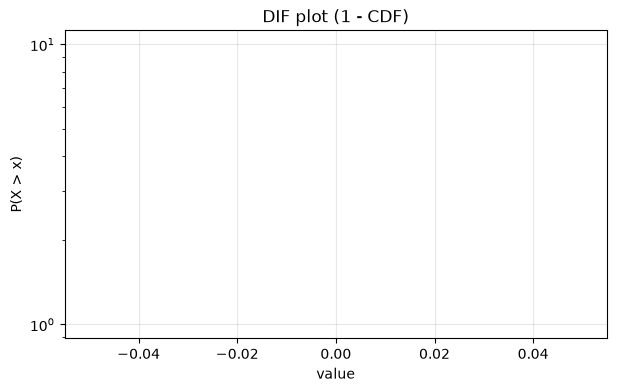

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(dif["value"], dif["surv"], where="post")
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
# ax.set_xscale("log")
ax.set_yscale("log")
plt.show()